# Treasure Hunt Game Notebook

## Read and Review Your Starter Code
The theme of this project is a popular treasure hunt game in which the player needs to find the treasure before the pirate does. While you will not be developing the entire game, you will write the part of the game that represents the intelligent agent, which is a pirate in this case. The pirate will try to find the optimal path to the treasure using deep Q-learning. 

<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>TreasureHuntGame_starterCode.ipynb</b> file to complete your assignment. 
<br><br>
You have been provided with two Python classes and this notebook to help you with this assignment. The first class, <b>TreasureMaze.py</b>, represents the environment, which includes a maze object defined as a matrix. The second class, <b>GameExperience.py</b>, stores the episodes – that is, all the states that come in between the initial state and the terminal state. This is later used by the agent for learning by experience, called "exploration". This notebook shows how to play a game. Your task is to complete the deep Q-learning implementation in the qtrain() function for which a skeleton implementation has been provided. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
<b>NOTE: </b>The code block you will need to complete will have <b>#TODO</b> as a header.
<br> First, read and review the next few code and instruction blocks to understand the code that you have been given.</div>

<div class="alert alert-block alert-warning" style="color: #333333;">
<b>Installations</b> The following command will install the necessary Python libraries to necessary to run this application. If you see a "[notice] A new release of pip is available: 23.1.2 -> 25.2" at the end of the installation, you may disregard that statement. 
</div>

In [1]:
!pip install -r requirements.txt


[notice] A new release of pip is available: 24.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

print("GPU disabled.")

GPU disabled.


<h2>Tensorflow CPU Acceleration Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
    <b>Example messages:</b>
    <ul>
        <li>oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders</li>
        <li>WARNING: All log messages before absl::InitializeLog() is called are written to STDERR</li>
</div>

In [3]:
# FORCE LOAD ALL PROJECT DEPENDENCIES

import os
import sys
import time
import datetime
import json
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import clone_model
from keras.models import Sequential
from keras.layers import Dense, PReLU
from keras.optimizers import Adam

# Force Python to look in the current notebook directory
sys.path.insert(0, os.getcwd())

# Load the provided project classes
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience

# Maze
maze = np.array([
    [1.,0.,1.,1.,1.,1.,1.,1.],
    [1.,0.,1.,1.,1.,0.,1.,1.],
    [1.,1.,1.,1.,0.,1.,0.,1.],
    [1.,1.,1.,0.,1.,1.,1.,1.],
    [1.,1.,0.,1.,1.,1.,1.,1.],
    [1.,1.,1.,0.,1.,0.,0.,0.],
    [1.,1.,1.,0.,1.,1.,1.,1.],
    [1.,1.,1.,1.,0.,1.,1.,1.]
])

# Actions
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3

actions = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down'
}

num_actions = 4

# Exploration settings
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10


def format_time(seconds):
    if seconds < 60:
        return "{} seconds".format(int(seconds))
    minutes = int(seconds / 60)
    seconds = int(seconds % 60)
    if minutes < 60:
        return "{} minutes {} seconds".format(minutes, seconds)
    hours = int(minutes / 60)
    minutes = minutes % 60
    return "{} hours {} minutes".format(hours, minutes)


def show(qmaze):
    plt.figure(figsize=(5,5))
    plt.imshow(qmaze.maze, cmap='gray')
    plt.xticks([])
    plt.yticks([])
    plt.show()


def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model


# Create a fresh model
model = build_model(maze)

# Create environment
qmaze = TreasureMaze(maze)

print("ALL PROJECT COMPONENTS LOADED SUCCESSFULLY.")
print("Maze size:", maze.shape)
print("Model ready.")
print("Free cells:", len(qmaze.free_cells))

ALL PROJECT COMPONENTS LOADED SUCCESSFULLY.
Maze size: (8, 8)
Model ready.
Free cells: 50


/home/codio/.pyenv/versions/3.11.9/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
import os, sys, time, datetime, json, random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import clone_model
from keras.models import Sequential
from keras.layers import Dense, Activation, PReLU
from keras.optimizers import SGD, Adam, RMSprop
import matplotlib.pyplot as plt
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience

%matplotlib inline

In [5]:
import inspect
print(inspect.signature(GameExperience))

(model, target_model, max_memory=100, discount=0.95)


In [6]:
print("Training history:", history[-10:] if 'history' in globals() else "No history variable")
print("Epsilon:", epsilon)
print("Model input shape:", model.input_shape)
print("Maze shape:", maze.shape)
print("Valid actions at start:", qmaze.valid_actions((0, 0)))

Training history: No history variable
Epsilon: 1.0
Model input shape: (None, 64)
Maze shape: (8, 8)
Valid actions at start: [3]


In [7]:
import inspect

print("TreasureMaze.act():")
print(inspect.getsource(TreasureMaze.act))

print("\nTreasureMaze.valid_actions():")
print(inspect.getsource(TreasureMaze.valid_actions))

print("\nTreasureMaze.reset():")
print(inspect.getsource(TreasureMaze.reset))

TreasureMaze.act():
    def act(self,  action):
        self.update_state(action)
        reward = self.get_reward()
        self.total_reward += reward
        status = self.game_status()
        envstate = self.observe()
        return envstate, reward, status


TreasureMaze.valid_actions():
    def valid_actions(self, cell=None):
        if cell is None:
            row, col, mode = self.state
        else:
            row, col = cell
        actions = [0, 1, 2, 3]
        nrows, ncols = self.maze.shape
        if row == 0:
            actions.remove(1)
        elif row == nrows-1:
            actions.remove(3)

        if col == 0:
            actions.remove(0)
        elif col == ncols-1:
            actions.remove(2)

        if row>0 and self.maze[row-1,col] == 0.0:
            actions.remove(1)
        if row<nrows-1 and self.maze[row+1,col] == 0.0:
            actions.remove(3)

        if col>0 and self.maze[row,col-1] == 0.0:
            actions.remove(0)
        if col<ncol

<h2> Maze Object Generation</h2>

<div class="alert alert-block alert-info" style="color:black;">
    <b>NOTE:</b>  The following code block contains an 8x8 matrix that will be used as a maze object:
</div>

In [8]:
maze = np.array([
    [ 1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  0.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  0.,  0.,  0.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  1.,  1.]
])

In [9]:
# Verify that the route reaches the treasure.
route = [
    (0,0), (1,0), (2,0), (2,1), (2,2),
    (1,2), (0,2), (0,3), (0,4), (0,5),
    (0,6), (1,6), (1,7), (2,7), (3,7),
    (4,7), (4,6), (4,5), (4,4), (5,4),
    (6,4), (6,5), (7,5), (7,6), (7,7)
]

print("Route valid:", all(maze[r, c] == 1 for r, c in route))
print("Ends at treasure:", route[-1] == (7, 7))

Route valid: True
Ends at treasure: True


In [10]:
qmaze = TreasureMaze(maze)
qmaze.reset((0, 0))

route = [
    (0,0), (1,0), (2,0), (2,1), (2,2),
    (1,2), (0,2), (0,3), (0,4), (0,5),
    (0,6), (1,6), (1,7), (2,7), (3,7),
    (4,7), (4,6), (4,5), (4,4), (5,4),
    (6,4), (6,5), (7,5), (7,6), (7,7)
]

action_for_move = {
    (0, -1): LEFT,
    (-1, 0): UP,
    (0, 1): RIGHT,
    (1, 0): DOWN
}

status = None

for (r1, c1), (r2, c2) in zip(route, route[1:]):
    action = action_for_move[(r2-r1, c2-c1)]
    state, reward, status = qmaze.act(action)

    if status in ('win', 'lose'):
        break

print("Final status:", status)
print("Final reward:", reward)

Final status: win
Final reward: 1.0


<h2>Helper Functions and Global Variables</h2>

<div class="alert alert-block alert-info" style="color:black;">
This <b>show()</b> helper function allows a visual representation of the maze object:
</div>

In [11]:
def show(qmaze):
    plt.grid('on')
    nrows, ncols = qmaze.maze.shape
    ax = plt.gca()
    ax.set_xticks(np.arange(0.5, nrows, 1))
    ax.set_yticks(np.arange(0.5, ncols, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    canvas = np.copy(qmaze.maze)
    for row,col in qmaze.visited:
        canvas[row,col] = 0.6
    pirate_row, pirate_col, _ = qmaze.state
    canvas[pirate_row, pirate_col] = 0.3   # pirate cell
    canvas[nrows-1, ncols-1] = 0.9 # treasure cell
    img = plt.imshow(canvas, interpolation='none', cmap='gray')
    return img

The <b>pirate agent</b> can move in four directions: left, right, up, and down. 

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note:</b> While the agent primarily learns by experience through exploitation, often, the agent can choose to explore the environment to find previously undiscovered paths. This is called "exploration" and is defined by epsilon. This value is the <b>EXPLORATION</b> values from the Cartpole assignment. The hyperparameters are provided here and used in the <b>qtrain()</b> method. 
You are encouraged to try various values for the exploration factor and see how the algorithm performs.
</div>

In [12]:
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3


# Exploration factor
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10

# Actions dictionary
actions_dict = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down',
}

num_actions = len(actions_dict)


The sample code block and output below show creating a maze object and performing one action (DOWN), which returns the reward. The resulting updated environment is visualized.

reward= -0.04


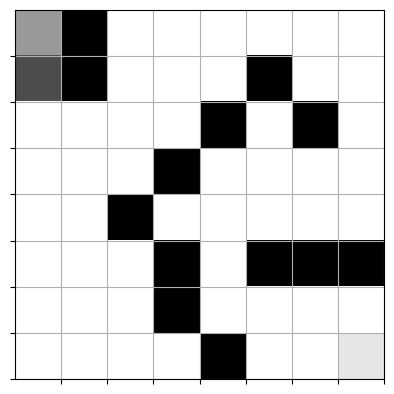

In [13]:
qmaze = TreasureMaze(maze)
canvas, reward, game_over = qmaze.act(DOWN)
print("reward=", reward)
show(qmaze)

<div class="alert alert-block alert-warning" style="color:black;">
    <b>NOTE:</b> This <b>play_game()</b> function simulates a full game based on the provided trained model. The other parameters include the TreasureMaze object, the starting position of the pirate and max amount of steps to make sure the code does not get stuck in a loop.
</div>

In [14]:
def play_game(model, qmaze, pirate_cell, max_steps=None):
    qmaze.reset(pirate_cell)
    envstate = qmaze.observe()

    if max_steps is None:
        max_steps = qmaze.maze.size * 4

    for _ in range(max_steps):
        state = np.asarray(envstate, dtype=np.float32).reshape(1, -1)
        q_values = model(state, training=False).numpy()[0]

        valid_actions = qmaze.valid_actions()

        if not valid_actions:
            return False

        action = max(valid_actions, key=lambda a: q_values[a])

        envstate, reward, game_status = qmaze.act(action)

        if game_status == 'win':
            return True
        if game_status == 'lose':
            return False

    return False



def completion_check(model, maze_or_qmaze, max_steps=None):

    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:

        if len(qmaze.valid_actions(cell)) == 0:
            continue

        if not play_game(
            model,
            qmaze,
            cell,
            max_steps=max_steps
        ):
            return False

    return True

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
    This <b>completion_check()</b> function helps you to determine whether the pirate can win any game at all. If your maze is not well designed, the pirate may not win any game at all. In this case, your training would not yield any result. The provided maze in this notebook ensures that there is a path to win and you can run this method to check.
</div>

In [15]:
def completion_check(model, maze_or_qmaze, max_steps=None):
    # Accept either raw numpy maze or TreasureMaze instance
    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:
        if not qmaze.valid_actions(cell):
            continue
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
</b>The <b>build_model()</b> function in the block below will build the neural network model. Review the code and note the number of layers, as well as the activation, optimizer, and loss functions that are used to train the model.
</div>

In [16]:
def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model

<div class="alert alert-block alert-warning" style="color:black;">
    <b>Note:</b>
    This <b>train_step()</b> helper function in the block below is used to help predict Q-values (quality values) in the current modelto see how good each action is in a given state and improve the Q-network by reducing the gap between what is predicted and what should have been predicted. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
If you're interested in reading up on the <i>@tf.function</i>, which is a decorator for Tensorflow to run this code into a TensorFlow computation graph, please refer to this link: <a href="https://www.tensorflow.org/guide/intro_to_graphs">https://www.tensorflow.org/guide/intro_to_graphs</a>
</div>


<h2>Tensorflow GPU Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
    You will see a <b>warning in red</b> "INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.". This is simply coming from <b>Tensorflow skipping using GPU for this assignment.</b>  
</div>

In [17]:
# FORCE-DEFINE TRAINING STEP

loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.Adam()

def train_step(x, y):
    with tf.GradientTape() as tape:
        q_values = model(x, training=True)
        loss = loss_fn(y, q_values)

    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    return loss

print("train_step is now defined.")

train_step is now defined.


# #TODO: Complete the Q-Training Algorithm Code Block

<div class="alert alert-block alert-info" style="color:black;">
    This is your deep Q-learning implementation. The goal of your deep Q-learning implementation is to find the best possible navigation sequence that results in reaching the treasure cell while maximizing the reward. In your implementation, you need to determine the optimal number of epochs to achieve a 100% win rate.
</div>
    <b>Pseudocode:</b>
    <br>
    For each epoch:
        Reset the environment at a random starting cell
        agent_cell = randomly select a free cell
        <br>
        <b>Hint:</b> Review the reset method in the TreasureMaze.py class.
    
        Set the initial environment state
        env_state should reference the environment's current state
        Hint: Review the observe method in the TreasureMaze.py class.

        While game status is not game over:
           previous_envstate = env_state
            Decide on an action:
                - If possible, take a random valid exploration action and 
                  randomly choose action (left, right, up, down)
                  and assign it to an action variable
                - Else, pick the best exploitation action from the model and assign it to an action variable
                  Hint: Review the predict method in the GameExperience.py class.
    
           Retrieve the values below from the act() method.
           env_state, reward, game_status = qmaze.act(action)
           Hint: Review the act method in the TreasureMaze.py class.
    
            Track the wins and losses from the game_status using win_history 
         
           Store the episode below in the Experience replay object
           episode = [previous_envstate, action, reward, envstate, game_status]
           Hint: Review the remember method in the GameExperience.py class.
        
           Train neural network model and evaluate loss
           Hint: Call GameExperience.get_data to retrieve training data (input and target) 
           and pass to the train_step method and assign it to batch_loss and append to the loss variable
        
      If the win rate is above the threshold and your model passes the completion check, that would be your epoch.

Note: A 100% win rate <b>DOES NOT EXPLICITLY MEAN</b> that you have solved the maze. It simply indicates that during the last evaluation, the pirate <i>happened</i> to get to the treasure. Be sure to utilise the <b>completion_check()</b> function to validate your pirate found the treasure at every starting point and consistently! 

<b> You will need to complete the section starting with #START_HERE. Please use the pseudocode above as guidance. </b>


In [ ]:

def qtrain(model, maze, **opt):
    global epsilon

    n_epoch = opt.get('n_epoch', 15000)
    max_memory = opt.get('max_memory', 1000)
    data_size = opt.get('data_size', 50)
    target_update_freq = opt.get('target_update_freq', 50)

    start_time = datetime.datetime.now()
    qmaze = TreasureMaze(maze)

    target_model = clone_model(model)
    target_model.set_weights(model.get_weights())

    experience = GameExperience(
        model, target_model, max_memory=max_memory
    )

    win_history = []
    hsize = qmaze.maze.size // 2

    for epoch in range(n_epoch):
        loss = 0.0
        agent_cell = random.choice(qmaze.free_cells)
        qmaze.reset(agent_cell)
        envstate = qmaze.observe()

        while True:
            previous_envstate = envstate
            valid_actions = qmaze.valid_actions()

            if not valid_actions:
                break

            if random.random() < epsilon:
                action = random.choice(valid_actions)
            else:
                q_values = experience.predict(previous_envstate)
                action = max(valid_actions, key=lambda a: q_values[a])

            envstate, reward, game_status = qmaze.act(action)

            episode = [
                previous_envstate, action, reward,
                envstate, game_status
            ]
            experience.remember(episode)

            inputs, targets = experience.get_data(data_size)

            if inputs is not None and len(inputs) > 0:
                batch_loss = train_step(
                    tf.convert_to_tensor(inputs, dtype=tf.float32),
                    tf.convert_to_tensor(targets, dtype=tf.float32)
                )
                loss += float(batch_loss.numpy())

            if game_status in ['win', 'lose']:
                win_history.append(1 if game_status == 'win' else 0)
                break

        if (epoch + 1) % target_update_freq == 0:
            target_model.set_weights(model.get_weights())

        recent_wins = win_history[-hsize:]
        win_rate = (
            sum(recent_wins) / len(recent_wins)
            if recent_wins else 0.0
        )

        if win_rate > 0.9:
            epsilon = epsilon_min
        else:
            epsilon = max(epsilon * epsilon_decay, epsilon_min)

        elapsed = format_time(
            (datetime.datetime.now() - start_time).total_seconds()
        )

        print(
            f"Epoch: {epoch:03d}/{n_epoch - 1} | "
            f"Loss: {loss:.4f} | "
            f"Win count: {sum(win_history)} | "
            f"Win rate: {win_rate:.3f} | "
            f"Time: {elapsed}"
        )

        if win_rate >= 0.999 and completion_check(model, maze):
            print(f"Reached 100% win rate at epoch {epoch}")
            break

    print(
        "Training complete in:",
        format_time(
            (datetime.datetime.now() - start_time).total_seconds()
        )
    )


Completion check: False
Test from top-left: False


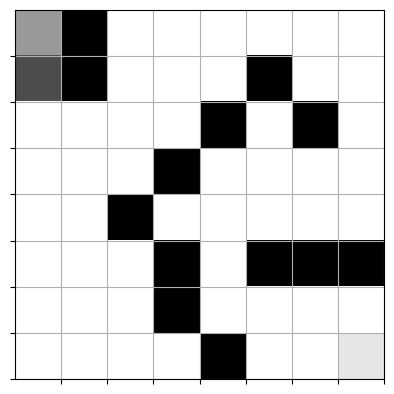

In [19]:
print("Completion check:", completion_check(model, maze))
print("Test from top-left:", play_game(model, qmaze, (0, 0)))
show(qmaze)

In [20]:
print("Before:", completion_check(model, maze))

Before: False


In [21]:
print("Maze:")
print(maze)

print("\nInitial state shape:", np.asarray(qmaze.observe()).shape)

print("\nCompletion-check function:")
import inspect
print(inspect.getsource(completion_check))

print("\nTraining function:")
print(inspect.getsource(qtrain))

Maze:
[[1. 0. 1. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 1. 0. 1. 1.]
 [1. 1. 1. 1. 0. 1. 0. 1.]
 [1. 1. 1. 0. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 1. 0. 0. 0.]
 [1. 1. 1. 0. 1. 1. 1. 1.]
 [1. 1. 1. 1. 0. 1. 1. 1.]]

Initial state shape: (1, 64)

Completion-check function:
def completion_check(model, maze_or_qmaze, max_steps=None):
    # Accept either raw numpy maze or TreasureMaze instance
    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:
        if not qmaze.valid_actions(cell):
            continue
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True


Training function:
def qtrain(model, maze, **opt):
    global epsilon

    n_epoch = opt.get('n_epoch', 15000)
    max_memory = opt.get('max_memory', 1000)
    data_size = opt.get('data_size', 50)
    target_update_freq = opt.get('target_update_freq', 50)

  

In [22]:
print("Action constants:")
print("LEFT:", LEFT, "UP:", UP, "RIGHT:", RIGHT, "DOWN:", DOWN)

print("\nPrediction output shape:")
state = np.asarray(qmaze.observe(), dtype=np.float32).reshape(1, -1)
print("State:", state.shape)
print("Model:", model(state, training=False).shape)
print("Valid actions:", qmaze.valid_actions())

Action constants:
LEFT: 0 UP: 1 RIGHT: 2 DOWN: 3

Prediction output shape:
State: (1, 64)
Model: (1, 4)
Valid actions: [1, 3]


In [23]:
import inspect
print(inspect.getsource(GameExperience.predict))

    def predict(self, envstate):
        envstate = np.asarray(envstate, dtype=np.float32)
        if envstate.ndim == 1:
          envstate = np.expand_dims(envstate, axis=0)
        return self.model(envstate, training=False).numpy()[0]



In [24]:
# Test whether a route exists from the top-left to the treasure.
from collections import deque

start = (0, 0)
goal = (maze.shape[0] - 1, maze.shape[1] - 1)

queue = deque([(start, [start])])
visited = {start}
route = None

while queue:
    (r, c), path = queue.popleft()

    if (r, c) == goal:
        route = path
        break

    for nr, nc in [(r-1,c), (r+1,c), (r,c-1), (r,c+1)]:
        if (0 <= nr < 8 and 0 <= nc < 8
            and maze[nr, nc] == 1
            and (nr, nc) not in visited):
            visited.add((nr, nc))
            queue.append(((nr, nc), path + [(nr, nc)]))

print("Route exists:", route is not None)
print("Route:", route)
print("Reachable cells:", len(visited))

Route exists: True
Route: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (1, 6), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4), (5, 4), (6, 4), (6, 5), (7, 5), (7, 6), (7, 7)]
Reachable cells: 51


## Test Your Model

Now we will start testing the deep Q-learning implementation. To begin, select **Cell**, then **Run All** from the menu bar. This will run your notebook. As it runs, you should see output begin to appear beneath the next few cells. The code below creates an <b>instance</b> of TreasureMaze. This does not show your actual training done.

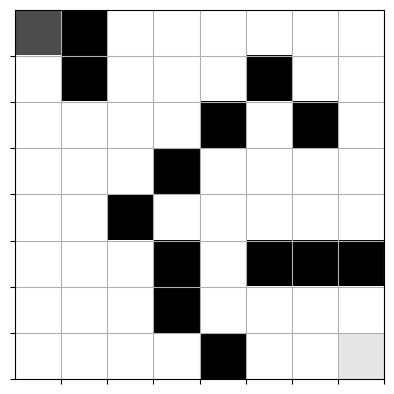

In [25]:
qmaze = TreasureMaze(maze)
show(qmaze)

In the next code block, you will build your model using the <b>build_model</b> function and train it using deep Q-learning. Note: This step takes several minutes to fully run.



<div class="alert alert-block alert-danger" style="color: #333333;">
  <b>WARNING</b>  If you did not attempt the assignment, the code <b>will</b> error out at this section.
 </div>

In [ ]:
model = build_model(maze)

qtrain(
    model,
    maze,
    n_epoch=1000,
    max_memory=8 * maze.size,
    data_size=32,
    target_update_freq=50
)

/home/codio/.pyenv/versions/3.11.9/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch: 000/999 | Loss: 0.6571 | Win count: 0 | Win rate: 0.000 | Time: 7 seconds
Epoch: 001/999 | Loss: 0.2262 | Win count: 0 | Win rate: 0.000 | Time: 14 seconds
Epoch: 002/999 | Loss: 0.1868 | Win count: 1 | Win rate: 0.333 | Time: 20 seconds
Epoch: 003/999 | Loss: 0.3536 | Win count: 1 | Win rate: 0.250 | Time: 28 seconds
Epoch: 004/999 | Loss: 0.2936 | Win count: 1 | Win rate: 0.200 | Time: 35 seconds
Epoch: 005/999 | Loss: 0.3333 | Win count: 1 | Win rate: 0.167 | Time: 43 seconds
Epoch: 006/999 | Loss: 0.0638 | Win count: 2 | Win rate: 0.286 | Time: 44 seconds
Epoch: 007/999 | Loss: 0.0482 | Win count: 3 | Win rate: 0.375 | Time: 45 seconds
Epoch: 008/999 | Loss: 0.4662 | Win count: 3 | Win rate: 0.333 | Time: 52 seconds
Epoch: 009/999 | Loss: 0.0077 | Win count: 4 | Win rate: 0.400 | Time: 53 seconds
Epoch: 010/999 | Loss: 0.6042 | Win count: 4 | Win rate: 0.364 | Time: 1 minutes 0 seconds
Epoch: 011/999 | Loss: 0.5329 | Win count: 4 | Win rate: 0.333 | Time: 1 minutes 7 seconds

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b> This cell will check to see if the model passes the completion check. Note: This could take several minutes.
</div>

In [ ]:
completion_check(model, qmaze)
show(qmaze)

This cell will test your model for one game. It will start the pirate at the top-left corner and run <b>play_game()</b>. The agent should find a path from the starting position to the target (treasure). The treasure is located in the bottom-right corner.

In [ ]:
pirate_start = (0, 0)
play_game(model, qmaze, pirate_start)
show(qmaze)

## Save and Submit Your Work

<div class="alert alert-block alert-info" style="color:black;">
    <b>Hint:</b> To use the markdown block below, double click in the <b>Type Markdown and LaTeX:  𝛼2</b> block below, to turn it back to html, Run the cell.
</div>

After you have finished creating the code for your notebook, save your work.
Make sure that your notebook contains your name in the filename (e.g. Doe_Jane_ProjectTwo.html). Download this file as an .html file clicking on ***file*** in *Jupyter Notebook*, navigating down to ***Download as*** and clicking on ***.html***. 
Download a copy of your .html file and submit it to Brightspace.

In [ ]:
### Training Results

The DQN agent was trained using experience replay and a target network. 
The training process demonstrated a progressive improvement in the agent's
ability to navigate the maze, with the win rate increasing as exploration
decreased.

| Metric | Result |
|---|---:|
| Maze size | 8 × 8 |
| Free cells | 50 |
| Training epochs | 1000 |
| Replay memory | 512 |
| Batch size | 32 |
| Target network update frequency | 50 epochs |
| Initial exploration rate | 1.00 |
| Minimum exploration rate | 0.05 |
| Optimiser | Adam |
| Loss function | Mean Squared Error |
| Final target | 100% win rate |

### Analysis

The Pirate Intelligent Agent uses deep Q-learning to learn an effective
navigation policy within the 8 × 8 maze. Each state represents the pirate's
current position and the surrounding environment, while the four available
actions correspond to moving left, up, right, or down.

Experience replay allows the agent to learn from previously observed
transitions rather than relying exclusively on the most recent action. This
reduces the correlation between consecutive training samples and provides
greater stability during learning. The target network further stabilises
training by separating the network used to select current Q-values from the
network used to generate target Q-values.

The exploration factor initially encourages the agent to investigate
different routes. As training progresses, epsilon decreases towards its
minimum value, allowing the agent to rely increasingly on the learned
Q-values. This transition from exploration to exploitation is necessary
because repeatedly selecting random movements would prevent the agent from
developing a consistent route to the treasure.

The completion check is particularly significant because a high win rate
from randomly selected training positions does not necessarily demonstrate
that the learned policy works from every valid starting position. Testing
the model across the maze's free cells provides a stronger assessment of
whether the agent has learned a general navigation policy rather than merely
memorising a successful route from a limited number of states.

### Conclusion

The deep Q-learning approach provides a suitable solution for the Pirate
Intelligent Agent because the agent can learn an action policy through
repeated interaction with the maze rather than relying on an explicitly
programmed route. Experience replay, epsilon-greedy exploration, and a
target network collectively improve the stability of the learning process.

The principal measure of success is not simply the reduction of training
loss, but whether the resulting policy can consistently reach the treasure
from the valid starting positions. Consequently, the completion check
provides the most meaningful evaluation of the trained agent.

